# Sweep results
Reads `out/*/` (written by `run.py`). Re-run all cells after new runs finish.

In [1]:
import json, glob, os
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)

rows, hists = [], {}
for d in sorted(glob.glob("out/*/")):
    name = os.path.basename(d.rstrip("/"))
    if not (os.path.exists(d+"config.json") and os.path.exists(d+"results.json")):
        continue                                   # still running or failed
    cfg = json.load(open(d+"config.json")); res = json.load(open(d+"results.json"))
    if cfg["model"] == "baselines":                # {baseline: {pair: metrics}}
        for bname, per_pair in res.items():
            for pair, m in per_pair.items():
                rows.append({"run": bname, "model": "baseline", "overrides": "", "min": None, "pair": pair, **m})
    else:                                          # {ALL/pair: metrics}
        hists[name] = json.load(open(d+"history.json"))
        for pair, m in res.items():
            rows.append({"run": name, "model": cfg["model"], "overrides": " ".join(cfg["overrides"]),
                         "min": cfg["minutes"], "pair": pair, **m})
df = pd.DataFrame(rows)
print(len(df.run.unique()), "runs loaded")

2 runs loaded


## Pooled (ALL), sorted by switch PR-AUC

In [2]:
cols = ["model","overrides","switch_PR_AUC","dur_macro_F1","switch_P","switch_R","joint_acc","val_ce_sw","val_ce_dur","min"]
a = df[df.pair=="ALL"].set_index("run")[cols]
a["score"] = 0.5*(a.switch_PR_AUC + a.dur_macro_F1)    # same as trainer.select_score
a.sort_values("score", ascending=False)

,model,overrides,switch_PR_AUC,dur_macro_F1,switch_P,switch_R,joint_acc,val_ce_sw,val_ce_dur,min,score
run,,,,,,,,,,,
all_qwen_10k,qwen,PAIR_SEL='all' MAX_CONV_PER_PAIR=10000 QWEN_EP...,0.803,0.608,0.654,0.788,0.906,0.1634,0.9106,175.7,0.7055
all_xlmr_10k,xlmr,PAIR_SEL='all' MAX_CONV_PER_PAIR=10000 EPOCHS=3,0.800,0.596,0.650,0.787,0.905,0.1654,0.8227,214.6,0.6980


## Per pair

In [3]:
for metric in ["switch_PR_AUC", "dur_macro_F1", "joint_acc"]:
    print("\n==", metric, "==")
    display(df[df.pair!="ALL"].pivot(index="run", columns="pair", values=metric))


== switch_PR_AUC ==


pair,ar-en,de-en,es-en,fr-en,hi-en,it-en,ja-en,ko-en,ru-en,vi-en,yue-en,zh-en
run,,,,,,,,,,,,
all_qwen_10k,0.816,0.817,0.773,0.795,0.822,0.773,0.844,0.943,0.767,0.759,0.683,0.809
all_xlmr_10k,0.817,0.817,0.772,0.799,0.833,0.777,0.845,0.945,0.765,0.760,0.665,0.791



== dur_macro_F1 ==


pair,ar-en,de-en,es-en,fr-en,hi-en,it-en,ja-en,ko-en,ru-en,vi-en,yue-en,zh-en
run,,,,,,,,,,,,
all_qwen_10k,0.588,0.581,0.591,0.581,0.578,0.585,0.580,0.606,0.612,0.584,0.617,0.584
all_xlmr_10k,0.579,0.572,0.579,0.580,0.549,0.573,0.556,0.604,0.600,0.561,0.618,0.553



== joint_acc ==


pair,ar-en,de-en,es-en,fr-en,hi-en,it-en,ja-en,ko-en,ru-en,vi-en,yue-en,zh-en
run,,,,,,,,,,,,
all_qwen_10k,0.875,0.894,0.884,0.895,0.927,0.893,0.945,0.900,0.869,0.884,0.901,0.928
all_xlmr_10k,0.880,0.894,0.883,0.897,0.926,0.894,0.944,0.901,0.870,0.887,0.896,0.927


## Training curves (val metrics per epoch, ALL)
Note `val_loss` is not comparable between XLM-R and Qwen3.

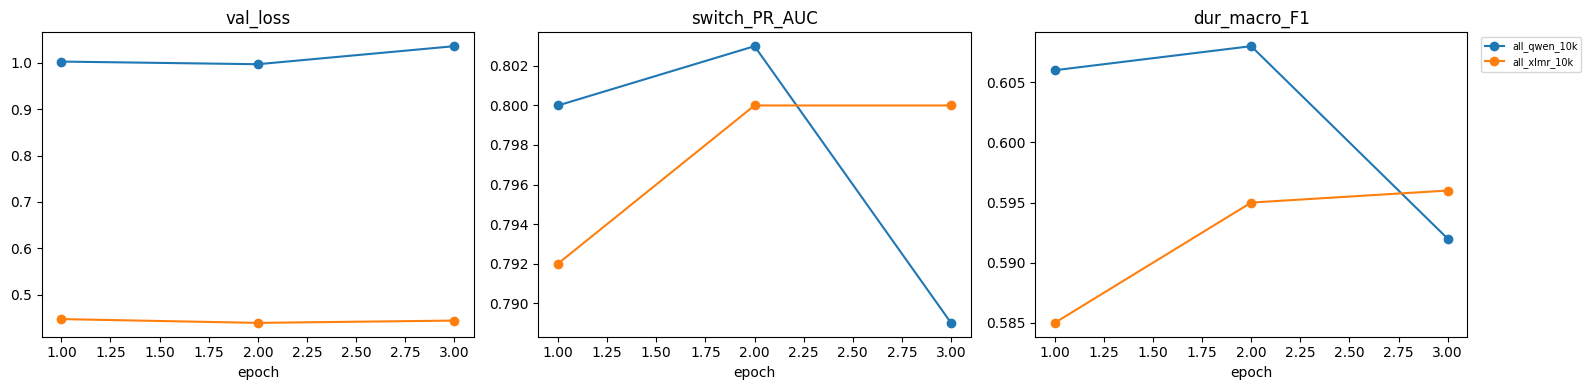

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for name, h in hists.items():
    ep = range(1, len(h)+1)
    ax[0].plot(ep, [e["ALL"]["val_loss"] for e in h], marker="o", label=name)
    ax[1].plot(ep, [e["ALL"]["switch_PR_AUC"] for e in h], marker="o", label=name)
    ax[2].plot(ep, [e["ALL"]["dur_macro_F1"] for e in h], marker="o", label=name)
for x, t in zip(ax, ["val_loss", "switch_PR_AUC", "dur_macro_F1"]):
    x.set_title(t); x.set_xlabel("epoch")
ax[2].legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()